# Praktikum 2 : kernel RBF dan ilustrasi tiga dimensi

In [6]:
# Langkah 1 - Ilustrasi Data Non-Linier

# Langkah 1a - Import Library
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [7]:
# Langkah 1b - Buat Kembali Fungsi Plotting
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    
    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

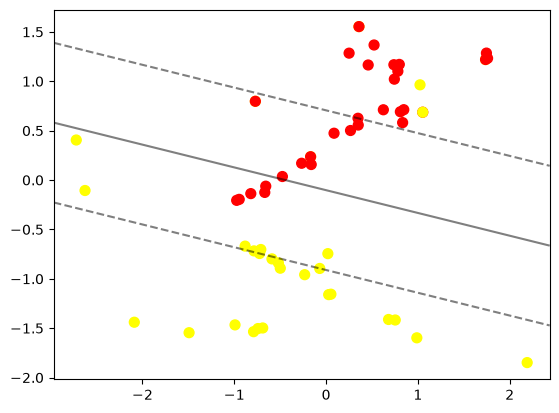

In [8]:
# Langkah 1c - Data PBL menggantikan make_circles
import pandas as pd
from sklearn.preprocessing import StandardScaler
data = pd.read_csv('../../dataset_pbl/cafes.csv')
data = data[data['source_query'].isin(['Cafe Soekarno Hatta Malang', 'Cafe Dinoyo Malang'])]
data = data.sample(frac=1, random_state=42).reset_index(drop=True)
X = StandardScaler().fit_transform(data[['latitude', 'longitude']])
y = data['source_query'].map({'Cafe Soekarno Hatta Malang': 0, 'Cafe Dinoyo Malang': 1}).to_numpy()
clf = SVC(kernel='linear').fit(X,y)
plt.scatter(X[:,0], X[:,1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False)

In [9]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    r = np.exp(-(X ** 2).sum(axis=1))
    ax = plt.figure().add_subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')
    plt.show()

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-0.94603257, -0.19555817],
       [ 0.5227228 ,  1.36726336],
       [-0.77030192,  0.79733945],
       [ 0.6805297 , -1.41167876],
       [ 0.79751225,  1.17074891],
       [ 0.35829191,  1.55361837],
       [ 0.98850996, -1.59738177],
       [-0.99169207, -1.46649464],
       [ 1.05281937,  0.68672376],
       [-2.72060743,  0.40537748],
       [-0.74132638, -1.50361153],
       [-2.62521484, -0.10591335],
       [-0.71075683, -0.7032689 ],
       [ 0.7385162 ,  1.16764299],
       [-0.16851037,  0.23606944],
       [ 0.80909538,  0.69156046],
       [ 0.83382023,  0.58147823],
       [-0.16851037,  0.23606944],
       [-0.72439446, -0.74375251],
       [ 0.34771832,  0.62556565],
       [-0.88172316, -0.66889043],
       [ 0.62383611,  0.71148812],
       [-0.51949345, -0.83862523],
       [ 1.73707432,  1.22007609],
       [-0.65693246, -0.06212229],
       [ 0.75323422, -1.41698964],
       [ 0.25073172,  1.28464834],
       [

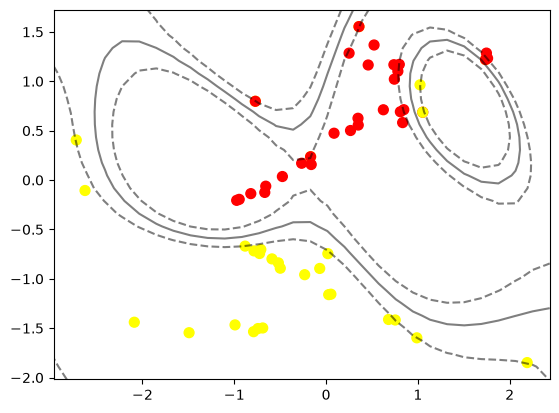

In [10]:
# Langkah 2 - Fitting Model

clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')